# Event recommender evaluation (Member 3)

Compares three ways to recommend events:

| Method | Idea |
|---|---|
| Collaborative filtering (ours) | "Students who behave like you are going here" (user-based, cosine similarity, 10 neighbours) |
| Content-only (baseline) | Event tags that match your interests, skills and goals |
| Popularity-only (baseline) | Most-attended events |

**Test:** hide 25% of all check-ins, ask each method for its top K, check whether the hidden events come back. Repeated over 10 random splits.

- **Hit Rate@K**: share of students for whom at least one hidden event is in the top K.
- **Precision@K**: share of the K recommendations that were really hidden events.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "events" / "checkins.py").exists():   # walk up to the repo root
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from events.checkins import EventStore
from eval.events.evaluate_events import evaluate, summarise, plot

store = EventStore()
print(len(store.events), "events,", len(store.students), "students,", len(store.going), "check-ins")

12 events, 65 students, 162 check-ins


In [2]:
warm, cold = evaluate(store, runs=10, test_share=0.25)
summary = summarise(warm)
summary

,method,k,hit_rate,hit_rate_std,precision,precision_std
0,Collaborative filtering,1,0.605,0.079,0.605,0.079
1,Collaborative filtering,3,0.844,0.087,0.315,0.038
2,Collaborative filtering,5,0.916,0.044,0.216,0.015
3,Content-only,1,0.661,0.110,0.661,0.110
4,Content-only,3,0.832,0.066,0.324,0.033
5,Content-only,5,0.894,0.051,0.214,0.013
6,Popularity-only,1,0.239,0.056,0.239,0.056
7,Popularity-only,3,0.376,0.052,0.139,0.020
8,Popularity-only,5,0.568,0.079,0.128,0.015


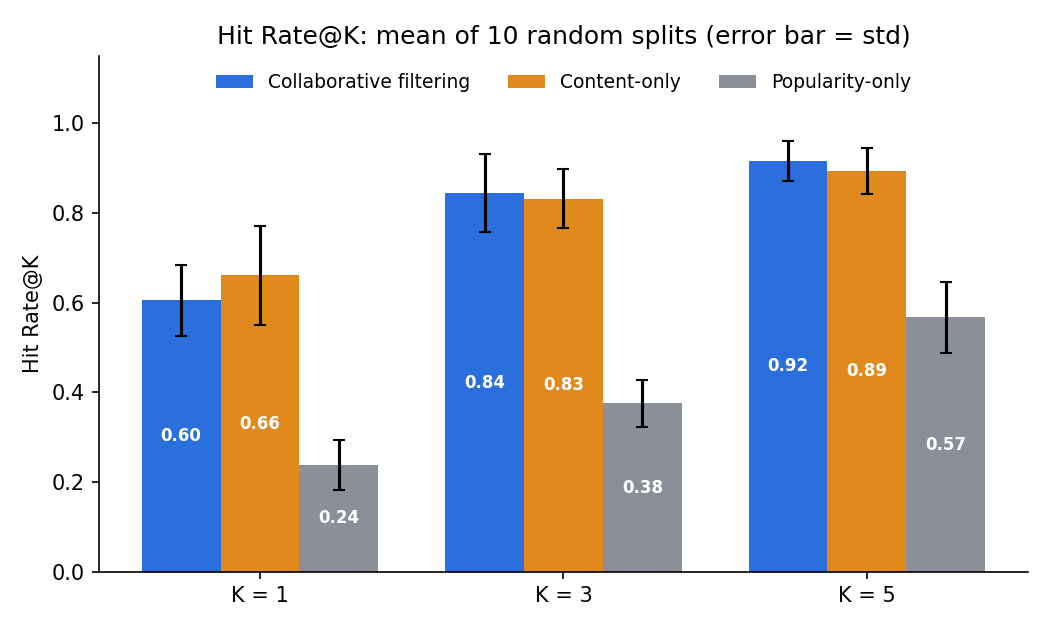

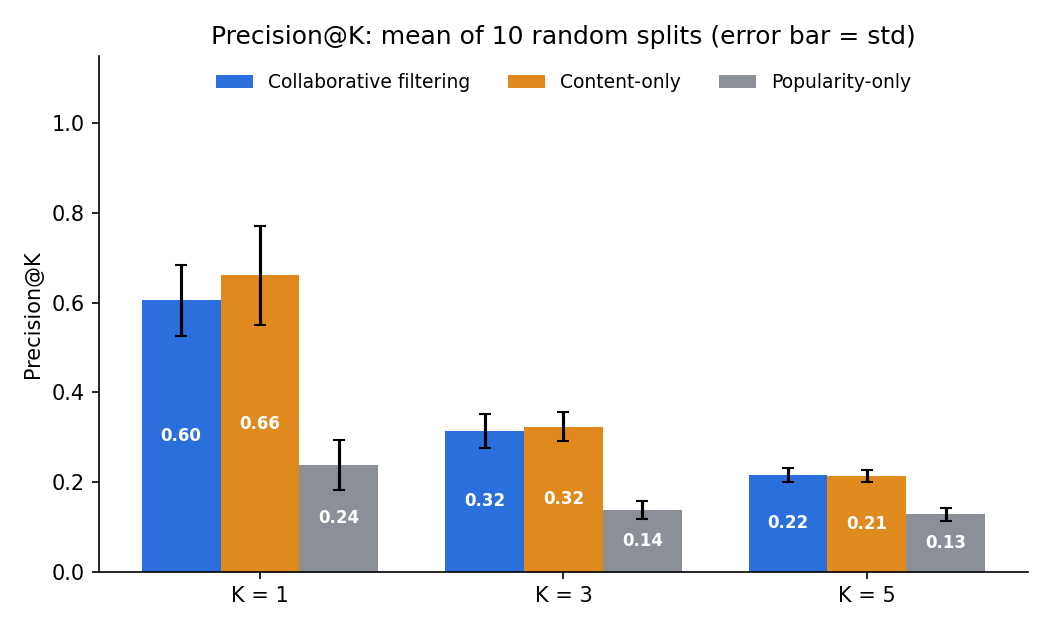

In [3]:
out = ROOT / "eval" / "events"
plot(summary, "hit_rate", "Hit Rate@K", out / "hit_rate_at_k.png")
plot(summary, "precision", "Precision@K", out / "precision_at_k.png")
from IPython.display import Image, display
display(Image(str(out / "hit_rate_at_k.png")))
display(Image(str(out / "precision_at_k.png")))

## Cold start: students with no visible history

When every check-in of a student is hidden, they look brand new. Collaborative filtering has nothing to learn from, so `recommend_events` falls back to content matching. That is why CF and content-only give the same numbers here.

In [4]:
summarise(cold) if len(cold) else "no cold-start cases in these splits"

,method,k,hit_rate,hit_rate_std,precision,precision_std
0,Collaborative filtering,1,0.578,0.261,0.578,0.261
1,Collaborative filtering,3,0.882,0.131,0.432,0.136
2,Collaborative filtering,5,0.882,0.131,0.267,0.083
3,Content-only,1,0.578,0.261,0.578,0.261
4,Content-only,3,0.882,0.131,0.432,0.136
5,Content-only,5,0.882,0.131,0.267,0.083
6,Popularity-only,1,0.255,0.226,0.255,0.226
7,Popularity-only,3,0.308,0.208,0.162,0.147
8,Popularity-only,5,0.445,0.278,0.151,0.104


## Reading the results (write this honestly in the report)

- Collaborative filtering clearly **beats the popularity baseline** at every K. This is the target in the project brief.
- Against **content-only** the two are close: CF is slightly better at K = 3 and K = 5, content is slightly better at K = 1. The difference is inside one standard deviation, so we do **not** claim CF is better than content matching.
- Why content does so well here: the synthetic students' interests come from the same tags that drive their attendance. Real students fill profiles less carefully, so we expect CF's advantage to grow with real data.
- Limits: 12 events, synthetic data. With 12 events, a top-5 list covers 40% of all events, which keeps hit rates high. Precision@5 is the more honest number.
- Next: add the pilot check-ins from Member 4 (`python -m eval.events.evaluate_events --attendance <file>`) and re-run.